In [1]:
#| include: false
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from utils.style import COLORS, CYCLE, apply_style

apply_style()
np.set_printoptions(precision=4, suppress=True, linewidth=110)
_ = pl.Config.set_float_precision(4)

Graphs show the whole distribution. **Summary measures** condense it into a few
numbers that describe its centre, its spread and its shape. We continue with the
Household Budget Survey of [the first part](01-freq-graphs.ipynb), and mainly
with the annual expenditure of each household, `exp_total`.

In [2]:
households = pl.read_csv("data/processed/epf/households.csv")

## Measures of centre

::: {.callout-note}
## Definition

- **Mean**: $\displaystyle \bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$.
- **Median** $Me$: the value that leaves half of the ordered observations below
  it.
- **Mode**: the most frequent value (or category).
:::

In [3]:
households.select(
    mean=pl.col("exp_total").mean(),
    median=pl.col("exp_total").median(),
)

mean,median
"35,705.2","31,089.4"


The mean is larger than the median. This is what we expect in a right-skewed
distribution: households with very high expenditure pull the mean upwards but
hardly affect the median.

The mode is the natural measure for qualitative or discrete variables:

In [4]:
households["household_size"].mode()

household_size
2


::: {.callout-caution}
## Robustness: mean versus median

Let us see what happens if we add **a single household** with an annual
expenditure of 5 million euros:

In [5]:
expenditure_with_outlier = pl.concat([households["exp_total"], pl.Series([5_000_000.0])])

pl.DataFrame({
    "measure": ["mean", "median"],
    "original": [households["exp_total"].mean(), households["exp_total"].median()],
    "with one more household": [expenditure_with_outlier.mean(), expenditure_with_outlier.median()],
})

measure,original,with one more household
mean,"35,705.2","35,957.1"
median,"31,089.4","31,089.5"


Even among almost 20,000 households, a single observation raises the mean by
about 250 €, while the median changes by less than one euro. In a small sample
the effect on the mean would be far larger. This is why official income
statistics usually report the **median income**. [Topic 5](../05-robust-statistics.qmd) makes this idea precise
(breakdown point, influence).
:::

## Measures of position: quantiles

::: {.callout-note}
## Definition

The **quantile** of order $p \in (0, 1)$, $Q_p$, is a value that leaves
(approximately) a proportion $p$ of the ordered observations below it. Special
cases:

- **Quartiles**: $Q_1 = Q_{0.25}$, $Q_2 = Q_{0.5} = Me$ and $Q_3 = Q_{0.75}$.
- **Percentiles**: $P_k = Q_{k/100}$. For example, $P_{90}$ is the expenditure
  exceeded by only 10 % of households.
:::

In [6]:
households.select(
    [pl.col("exp_total").quantile(p, interpolation="linear").alias(f"Q_{p}")
     for p in [0.10, 0.25, 0.50, 0.75, 0.90]]
)

Q_0.1,Q_0.25,Q_0.5,Q_0.75,Q_0.9
"15,199.8","21,490.7","31,089.4","44,847.1","61,388.2"


::: {.callout-tip}
## There are several definitions of a quantile

With finite samples there are different conventions for computing a quantile, and
each program uses its own by default. @hyndman1996 compared nine of them, all
used by some statistical package. Polars uses `interpolation="nearest"` unless
told otherwise; here we use `"linear"`, which is the default in NumPy and R
(type 7 in Hyndman and Fan's classification). With large samples the differences
between definitions are small.
:::

## Measures of dispersion

Two variables can have the same mean and very different variability.

::: {.callout-note}
## Definition

- **Range**: $R = x_{(n)} - x_{(1)}$, the difference between the maximum and the
  minimum.
- **Variance**: $\displaystyle s^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^2$.
- **Standard deviation**: $s = \sqrt{s^2}$. It is measured in the same units as
  the data.
- **Corrected (sample) variance**:
  $\displaystyle \hat{s}^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2$. It is
  the unbiased estimator of the population variance, studied in statistical
  inference.
- **Interquartile range**: $IQR = Q_3 - Q_1$, the width of the central 50 % of the
  data.
- **Coefficient of variation**: $CV = s / |\bar{x}|$. It has no units, so it can
  compare the spread of variables measured on different scales (for ratio-scale
  variables).
:::

In [7]:
x = pl.col("exp_total")

households.select(
    range=x.max() - x.min(),
    variance=x.var(ddof=0),
    std_dev=x.std(ddof=0),
    corrected_variance=x.var(ddof=1),
    IQR=x.quantile(0.75, "linear") - x.quantile(0.25, "linear"),
    CV=x.std(ddof=0) / x.mean(),
)

range,variance,std_dev,corrected_variance,IQR,CV
"326,033.2","426,739,110.6","20,657.7","426,760,770.2","23,356.4",0.579


::: {.callout-important}
## Watch out for `ddof`

Polars (like pandas and R) computes the **corrected variance** by default, that
is, it divides by $n-1$. To obtain the variance as defined above we need
`ddof=0`. With almost 20,000 households the difference is negligible, but with
small samples it is not.
:::

The coefficient of variation compares the spread of total expenditure with that
of food expenditure, whose means are very different:

In [8]:
households.select(
    pl.col("exp_total", "exp_food").std(ddof=0)
    / pl.col("exp_total", "exp_food").mean()
)

exp_total,exp_food
0.579,0.742


Food expenditure is relatively more dispersed than total expenditure. Part of the
reason is how it is measured: food purchases are recorded in a diary for two
weeks and then converted into an annual amount, so a household that did a big
shopping trip in those two weeks looks like a big spender.

## Measures of shape

::: {.callout-note}
## Definition

- **Skewness coefficient**:
  $\displaystyle g_1 = \frac{\frac{1}{n}\sum (x_i-\bar{x})^3}{s^3}$. It is 0 for a
  symmetric distribution, positive for right skewness and negative for left
  skewness.
- **(Excess) kurtosis coefficient**:
  $\displaystyle g_2 = \frac{\frac{1}{n}\sum (x_i-\bar{x})^4}{s^4} - 3$. It compares
  the weight of the tails with that of a normal distribution, for which
  $g_2 = 0$.
:::

In [9]:
households.select(
    skewness=pl.col("exp_total").skew(),
    kurtosis=pl.col("exp_total").kurtosis(),  # already subtracts 3
)

skewness,kurtosis
1.973,8.854


The positive skewness confirms numerically what the histogram showed.

## Boxplot and outliers

The **boxplot** summarises in a single graph the median, the quartiles and the
possible outliers:

- The box goes from $Q_1$ to $Q_3$, and the inner line marks the median.
- The "whiskers" reach the most extreme observations within the fences
  $$
  LF = Q_1 - 1.5 \cdot IQR, \qquad UF = Q_3 + 1.5 \cdot IQR.
  $$
- Observations outside $[LF, UF]$ are flagged as **outliers**.

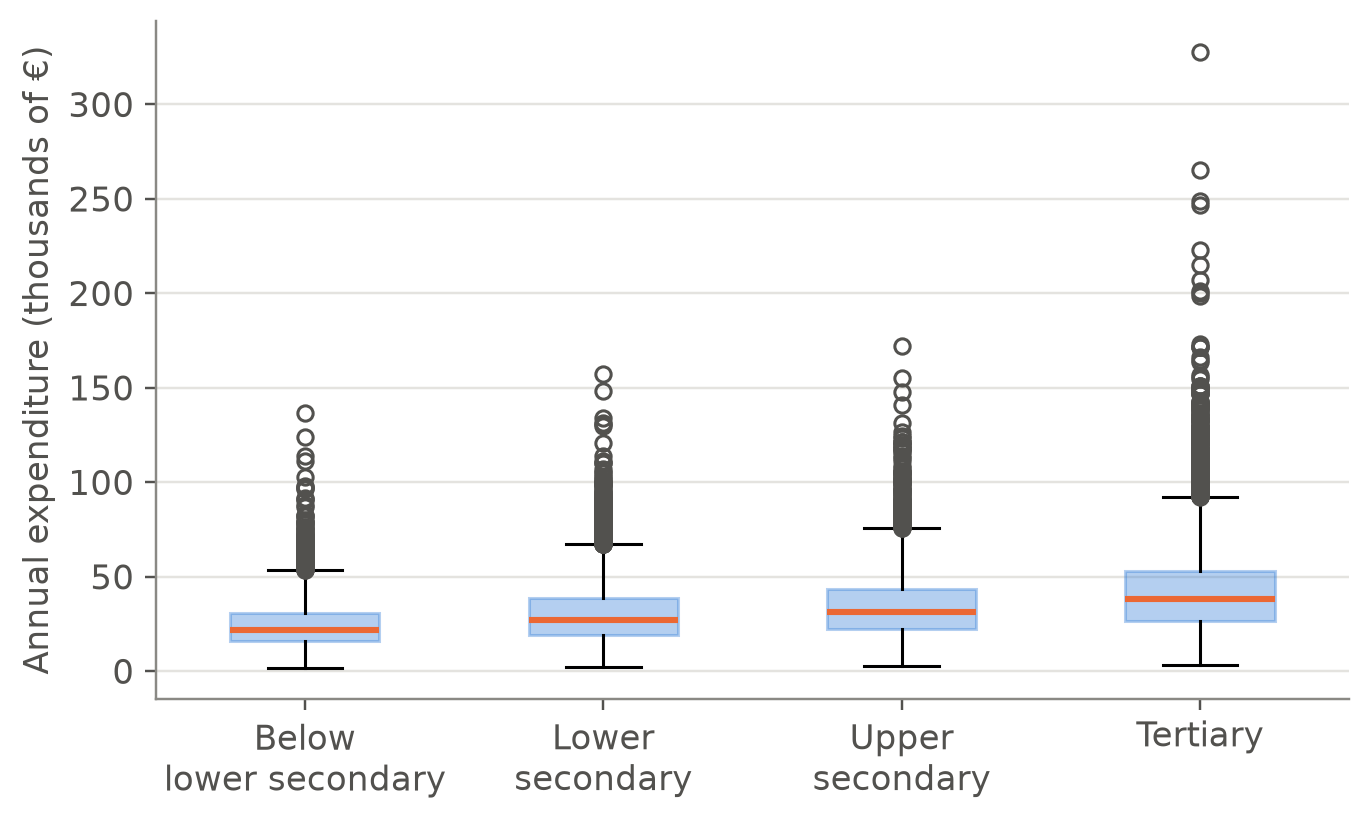

In [10]:
#| label: fig-boxplot-expenditure
#| fig-cap: "Boxplots of annual household expenditure by education level of the reference person."
levels = ["Below lower secondary", "Lower secondary", "Upper secondary", "Tertiary"]
groups = [
    households.filter(pl.col("ref_education") == level)["exp_total"] / 1000
    for level in levels
]

fig, ax = plt.subplots()
ax.boxplot(
    groups, tick_labels=[level.replace(" ", "\n", 1) for level in levels],
    widths=0.5, patch_artist=True,
    boxprops=dict(facecolor=COLORS["blue"], alpha=0.35, edgecolor=COLORS["blue"]),
    medianprops=dict(color=COLORS["orange"], linewidth=2),
    flierprops=dict(marker="o", markersize=5, markerfacecolor="none",
                    markeredgecolor=COLORS["ink_soft"]),
)
ax.set_ylabel("Annual expenditure (thousands of €)")
plt.show()

Boxplots are especially useful for **comparing groups**. In
@fig-boxplot-expenditure, both the median and the spread of expenditure increase
with the education level of the reference person.

::: {.callout-note}
## Historical note: Tukey's box-and-whisker plot

John Tukey introduced the box-and-whisker plot as part of his programme of
*exploratory data analysis*, in a preliminary edition circulated in 1970 and in
the book of 1977 [@tukey1977]. Tukey wanted quick graphs that could be drawn by
hand and that were resistant to outliers, which is why the box is built from
quartiles and not from the mean and standard deviation. The 1.5 × IQR rule was
his pragmatic choice. Variants such as notched and variable-width boxplots
appeared soon afterwards [@mcgill1978].
:::

Outliers can also be identified from their definition:

In [11]:
q1, q3 = households.select(
    q1=pl.col("exp_total").quantile(0.25, "linear"),
    q3=pl.col("exp_total").quantile(0.75, "linear"),
).row(0)
iqr = q3 - q1
lf, uf = q1 - 1.5 * iqr, q3 + 1.5 * iqr

outliers = households.filter(~pl.col("exp_total").is_between(lf, uf))
print(f"Fences: [{lf:,.0f}, {uf:,.0f}] €  ·  Outliers: {outliers.height}")

Fences: [-13,544, 79,882] €  ·  Outliers: 717


The lower fence is negative, so expenditure can only have outliers at the top,
which is common in right-skewed distributions.

::: {.callout-warning}
## An outlier is not necessarily an error

An outlier may be a measurement error, but it may also be a household with a
genuinely high expenditure. Before removing observations, we have to understand why
they are outlying. In a right-skewed distribution the 1.5 × IQR rule flags many
perfectly valid observations.
:::

## Linear transformations

It is common to change the scale of a variable (from euros to thousands of euros,
from nominal to real prices, from °F to °C…). If $y_i = a + b\,x_i$, then
$$
\bar{y} = a + b\,\bar{x}, \qquad s_y = |b|\, s_x .
$$ {#eq-linear-transformation}

::: {.callout-note collapse="true"}
## Proof

$\bar y = \frac1n\sum_i (a + bx_i) = a + b\bar x$. Then
$y_i - \bar y = b(x_i - \bar x)$, so
$s_y^2 = \frac1n\sum_i b^2(x_i-\bar x)^2 = b^2s_x^2$, and $s_y = |b|s_x$.
:::

A special case is **standardisation**, $z_i = (x_i - \bar{x})/s_x$, which produces
a variable with mean 0 and standard deviation 1:

In [12]:
households.select(
    z=(pl.col("exp_total") - pl.col("exp_total").mean())
      / pl.col("exp_total").std(ddof=0)
).select(mean=pl.col("z").mean(), std_dev=pl.col("z").std(ddof=0))

mean,std_dev
-0.000,1.000


The value $z_i$ tells how many standard deviations observation $i$ lies from the
mean.

## Summary of the topic

| Type of variable | Tables | Graphs | Measures |
|---|---|---|---|
| Qualitative nominal | $n_i$, $f_i$ | Bar chart | Mode |
| Qualitative ordinal | $n_i$, $f_i$, $N_i$, $F_i$ | Bar chart | Mode, median, quantiles |
| Quantitative discrete | $n_i$, $f_i$, $N_i$, $F_i$ | Bar chart | All |
| Quantitative continuous | By classes | Histogram, boxplot | All |

The exercises for this topic are in [part 3](03-exercises.ipynb).

## References {.unnumbered}

::: {#refs}
:::